# Kepler vetting: noise floor and error analysis (10/10/2026)

**Step 1, noise floor:** how much do the baseline MLP's scores move from luck alone (model seed, which stars land
in validation, fold choice)? That sets the bar any later change (steps 3–5) has to clear.

**Step 2, error analysis:** using an out-of-fold score for every KOI in the pool, where does the model fail and what
kinds of false positives does it miss?

Setup: baseline from `exo100926` (11 features, 64-32 MLP, dropout 0.2, Adam 1e-3, batch 128, early stopping with
patience 25). Heavy compute ran headless in `sweeps/cv_noise_floor.jl`; this notebook only loads and analyzes it.
**The test split (split seed 42) is never used here.**

## Key results
- **Baseline:** pooled out-of-fold ROC-AUC **0.925** (95% star-bootstrap CI 0.919–0.931); **0.964** on CONFIRMED vs FP.
  exo100926's 0.928 was a typical draw, not a lucky one.
- **A single notebook run can't rank models.** On a ~930-KOI validation set, *which stars land in validation* moves
  ROC-AUC by ±0.007 (range 0.914–0.943), five times more than the model seed (±0.0016). Two single runs need to differ by
  ≳0.02 before it means anything.
- **With repeated CV it can.** On identical folds, two runs of the same config differ by < 0.0005 (95%). From here on,
  compare configs with `cv_run` + `compare_cv`, and require the paired star-bootstrap CI to exclude 0 as well.
- **Seed ensembling** adds only +0.0017 AUC and saturates by ~5 seeds; use 5 seeds for comparisons.
- **The sealed test set (~910 KOIs) has ±0.009 AUC sampling error on its own**, so use it once, at the end, as a check rather than to choose between models.
- **Errors are concentrated, not uniform:**
  1. *Supplemental KOIs* (not re-detected by the final DR25 pipeline, no `koi_score`): 13% of KOIs, a third of all
     errors, AUC **0.65**, vs **0.948** for DR25 KOIs. The 570 found only by the old Q1–Q16 run score AUC 0.56.
  2. *Eclipsing binaries are largely solved*: only 4.5% of pure stellar-eclipse (SS) FPs get through; odd/even-depth and
     V-shaped FPs are caught ≥ 97% of the time, secondary-eclipse FPs 91–93%.
  3. *Centroid-offset / contamination FPs are the main blind spot* (38% of CO-only FPs missed; CO/EC flags on 58% of all
     missed FPs). Nothing in the 11 catalog features measures where on the sky the signal comes from.
  4. *The multiplicity prior is very strong*: FPs in systems with ≥ 3 KOIs are missed 74–100% of the time, while 94% of
     missed planets are in single-KOI systems.
  5. *Most "missed planets" are CANDIDATEs* (82%); CONFIRMED planets are recovered 95% of the time. Many of the lowest-scored
     CANDIDATEs are physically implausible (R > 25 R⊕, grazing) and likely label noise; the rest are small
     ultra-short-period signals, the same blind spot that costs the model some confirmed USP planets (70% of planets
     with P < 1.5 d are called FPs).
- **Robustness (section 3):** all of these hold across 5 independent fold shuffles. Findings 2–4 also hold on DR25
  KOIs alone, where the baseline reaches AUC 0.948 (CI 0.943–0.952). The long-period and low-SNR weak spots are
  mostly a supplemental-KOI effect.

In [1]:
include(joinpath(@__DIR__, "..", "src", "VettingSetup.jl"))
df_raw = load_koi()
df = clean_koi(df_raw)
pool, _ = cv_pool(df)                        # train+val of the main split; test stays sealed
cv = load_cv("cv_baseline_r5s10.jld2")
@assert cv.kepoi == pool.kepoi_name
single = JLD2.load(joinpath(CV_DIR, "single_split_runs.jld2"), "single")
R, S, K = size(cv.oof, 2), size(cv.oof, 3), maximum(cv.folds)
println("pool: $(nrow(pool)) KOIs on $(length(unique(pool.kepid))) stars")
println("CV: $K folds × $R fold shuffles × $S model seeds = $(nrow(cv.results)) trained models")

VettingSetup loaded:11 features, data at C:\JuliaProjects\Exoplanet vetting\data\koi_cumulative.csv
┌ Info: clean_koi
│   raw = 9564
│   kept = 9201
│   stars = 7927
│   planets = 4619
└   false_pos = 4582
pool: 8288 KOIs on 7135 stars
CV: 5 folds × 5 fold shuffles × 10 model seeds = 250 trained models


## 1. Noise floor
### 1.1 Single models on held-out folds (~1,660 KOIs each)
Each row summarizes all 250 models. `*_conf` = CONFIRMED vs FALSE POSITIVE only (CANDIDATEs dropped).

In [2]:
metric_cols = [:roc_auc, :pr_auc, :accuracy, :f1, :logloss, :roc_auc_conf, :pr_auc_conf, :best_epoch]
DataFrame(metric = string.(metric_cols),
          mean = [mean(cv.results[!, c]) for c in metric_cols],
          std  = [std(cv.results[!, c]) for c in metric_cols],
          min  = [minimum(cv.results[!, c]) for c in metric_cols],
          max  = [maximum(cv.results[!, c]) for c in metric_cols])

Row,metric,mean,std,min,max
,String,Float64,Float64,Real,Real
1,roc_auc,0.92274,0.00468055,0.910102,0.933175
2,pr_auc,0.918995,0.00637693,0.901068,0.933057
3,accuracy,0.839267,0.00775253,0.821622,0.861011
4,f1,0.840928,0.00849011,0.824156,0.863556
5,logloss,0.353543,0.0104525,0.329095,0.378957
6,roc_auc_conf,0.96177,0.00447666,0.951847,0.973868
7,pr_auc_conf,0.934241,0.00904687,0.910277,0.954085
8,best_epoch,102.244,36.4707,26,200


### 1.2 Where the spread comes from (ROC-AUC)

In [3]:
ns = noise_summary(cv, pool)
pair_diffs = [ns.single[r, f, s1] - ns.single[r, f, s2] for r in 1:R, f in 1:K, s1 in 1:S, s2 in 1:S if s1 < s2]
nulls = null_differences(cv, pool; n = 500)
noise_tbl = DataFrame(
    source = ["single model, one fold (std over all 250)",
              "model seed only (std across seeds, fold fixed)",
              "two single models on the same fold (std of difference)",
              "fold-to-fold (10-seed ensemble per fold)",
              "pooled OOF, single seed (std over repeats × seeds)",
              "pooled OOF, 10-seed ensemble (std over 5 fold shuffles)",
              "null: 5-seed vs 5-seed ensembles, all repeats (std)",
              "null: 95th percentile of |difference|"],
    roc_auc = [std(ns.single), ns.seed_std_within_fold, std(pair_diffs), ns.fold_std_ens,
               std(ns.pooled_single), std(ns.pooled_ens), std(nulls), quantile(abs.(nulls), 0.95)])
println(@sprintf("final pooled OOF ROC-AUC (50 models per KOI): %.4f", ns.final))
println(@sprintf("mean single-model fold AUC %.4f -> 10-seed ensemble %.4f  (gain %+.4f)",
                 mean(ns.single), mean(ns.ens), ns.ensemble_gain))
noise_tbl

final pooled OOF ROC-AUC (50 models per KOI): 0.9251
mean single-model fold AUC 0.9227 -> 10-seed ensemble 0.9243  (gain +0.0016)


Row,source,roc_auc
,String,Float64
1,"single model, one fold (std over all 250)",0.00468055
2,"model seed only (std across seeds, fold fixed)",0.00136999
3,two single models on the same fold (std of difference),0.00205274
4,fold-to-fold (10-seed ensemble per fold),0.00461758
5,"pooled OOF, single seed (std over repeats × seeds)",0.000866605
6,"pooled OOF, 10-seed ensemble (std over 5 fold shuffles)",0.000581427
7,"null: 5-seed vs 5-seed ensembles, all repeats (std)",0.000264235
8,null: 95th percentile of |difference|,0.000477071


**Reading this:** a single model scored on one fold varies by ±0.005, and almost all of that comes from *which KOIs are in
the fold* (fold-to-fold ±0.0046), not from training randomness (seed ±0.0014). Once predictions are pooled over all
~8,300 KOIs, training noise nearly disappears (±0.0009 for one seed, ±0.0006 for a 10-seed ensemble), and two
5-seed runs of the same config agree to within 0.0005 (95%).

### 1.3 Notebook-style runs: how lucky was exo100926?
20 model seeds on the exact exo100926 split, and 20 different train/val re-splits of the pool (same sizes, model
seed 1). Each point is one validation ROC-AUC on ~930 KOIs, i.e. exactly what one notebook run reports.

2×8 DataFrame
 Row │ kind                       runs   auc_mean  auc_std     auc_min   auc_max   conf_mean  conf_std
     │ String                     Int64  Float64   Float64     Float64   Float64   Float64    Float64
─────┼───────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ model seed (split 42)         20  0.926373  0.00157032  0.923349  0.929683   0.961386  0.00154943
   2 │ split seed (model seed 1)     20  0.927312  0.00724604  0.91418   0.942947   0.964681  0.00514795


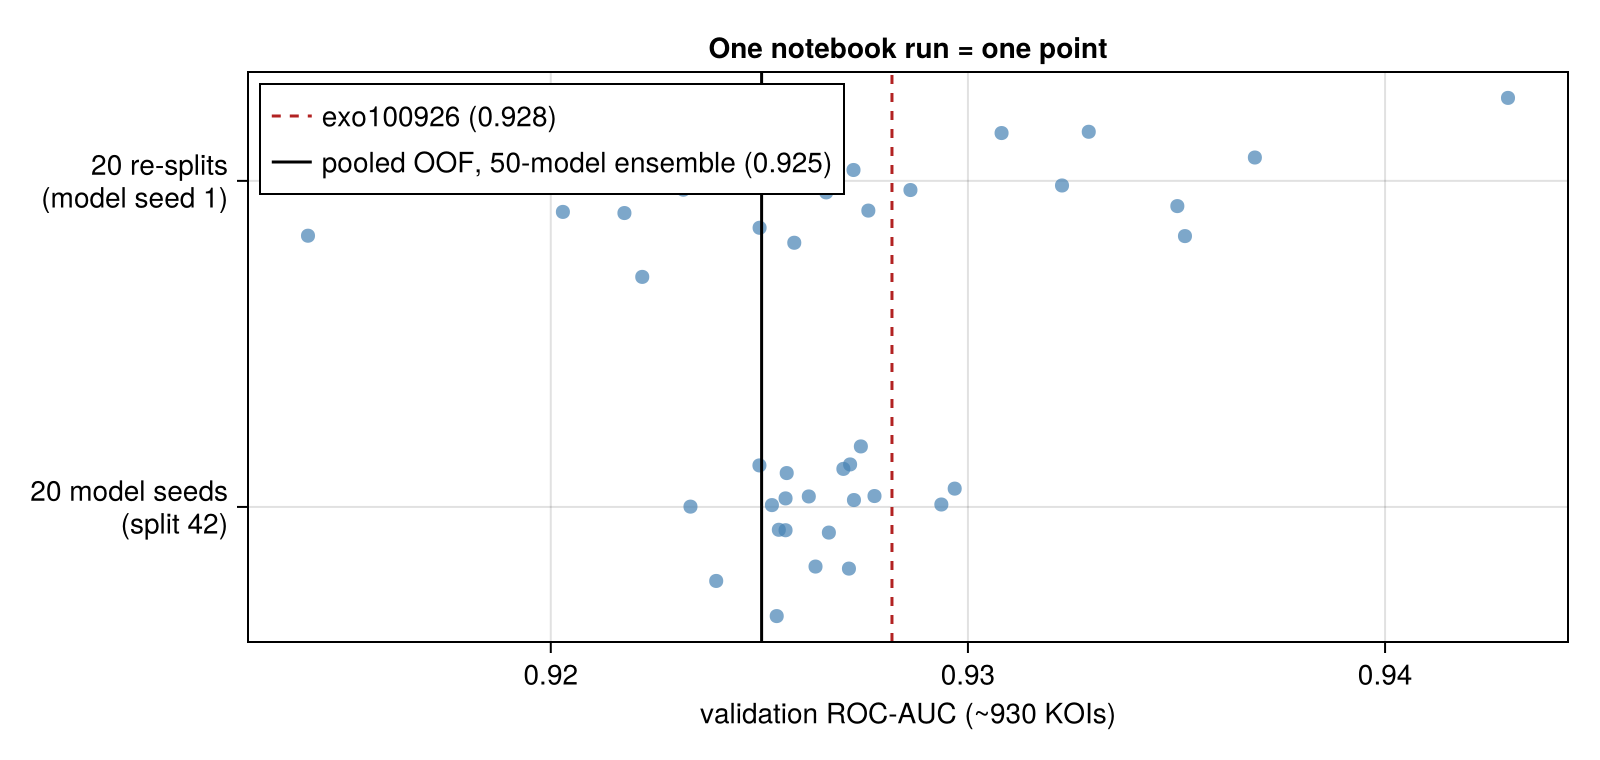

In [4]:
println(combine(groupby(single, :kind), nrow => :runs,
                :roc_auc => mean => :auc_mean, :roc_auc => std => :auc_std,
                :roc_auc => minimum => :auc_min, :roc_auc => maximum => :auc_max,
                :roc_auc_conf => mean => :conf_mean, :roc_auc_conf => std => :conf_std))
fig = Figure(size = (800, 380))
ax = Axis(fig[1, 1]; xlabel = "validation ROC-AUC (~930 KOIs)", yticks = (1:2, ["20 model seeds\n(split 42)", "20 re-splits\n(model seed 1)"]),
          title = "One notebook run = one point")
for (i, kind) in enumerate(unique(single.kind))
    x = single.roc_auc[single.kind .== kind]
    scatter!(ax, x, i .+ 0.12 .* randn(Xoshiro(i), length(x)); markersize = 10, color = (:steelblue, 0.7))
end
vlines!(ax, [0.928179]; color = :firebrick, linestyle = :dash, label = "exo100926 (0.928)")
vlines!(ax, [ns.final]; color = :black, label = @sprintf("pooled OOF, 50-model ensemble (%.3f)", ns.final))
axislegend(ax; position = :lt)
savefig("exo101026_single_runs.png", fig)
fig

**Reading this:** with the split fixed, 20 seeds span 0.923–0.930 (exo100926's 0.928 is inside that range). Re-drawing the
validation stars spans 0.914–0.943. So a notebook comparison like "0.928 → 0.935" is well within luck; comparisons
need the CV protocol below.

### 1.4 Ensembling and the null distribution
Left: pooled OOF ROC-AUC vs number of seeds averaged (mean over 5 fold shuffles and 20 random seed subsets).
Right: the gap between two runs of the **same** config (5 seeds each, identical folds). A real improvement in
steps 3–5 has to land clearly outside this.

ensemble curve: [0.9224, 0.9233, 0.9236, 0.9238, 0.9239, 0.924, 0.924, 0.924, 0.924, 0.9241]


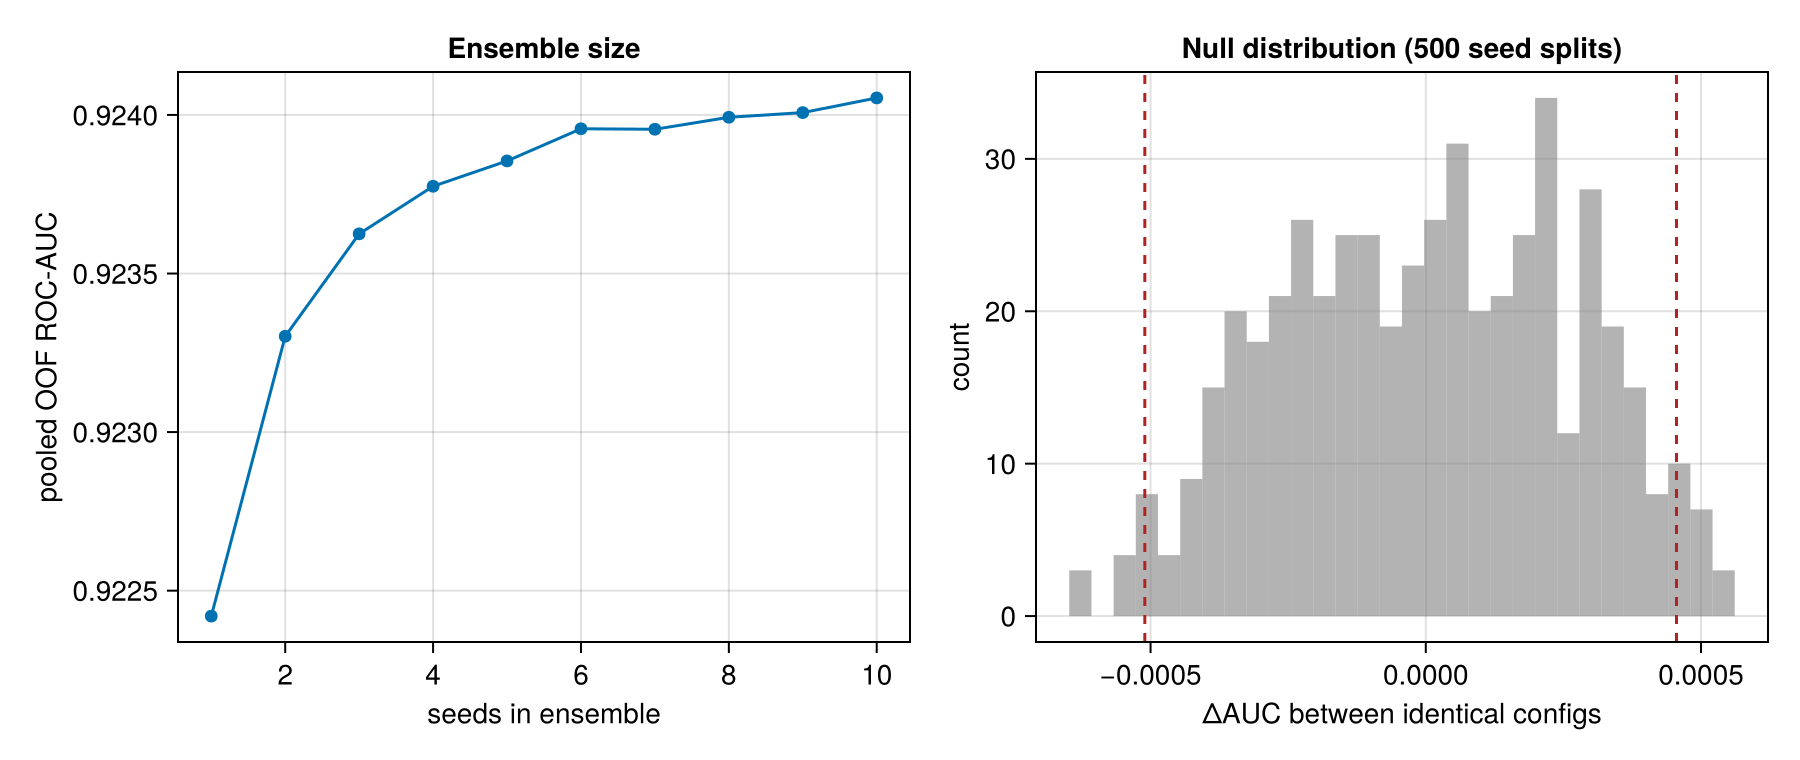

In [5]:
ens_curve = map(1:S) do m
    rng = Xoshiro(m)
    mean(fast_auc(pool.label, vec(mean(cv.oof[:, r, randperm(rng, S)[1:m]]; dims = 2))) for r in 1:R, _ in 1:20)
end
fig = Figure(size = (900, 380))
a1 = Axis(fig[1, 1]; xlabel = "seeds in ensemble", ylabel = "pooled OOF ROC-AUC", title = "Ensemble size")
scatterlines!(a1, 1:S, ens_curve)
a2 = Axis(fig[1, 2]; xlabel = "ΔAUC between identical configs", ylabel = "count", title = "Null distribution (500 seed splits)")
hist!(a2, nulls; bins = 30, color = (:gray, 0.6))
vlines!(a2, quantile(nulls, [0.025, 0.975]); color = :firebrick, linestyle = :dash)
savefig("exo101026_ensemble_null.png", fig)
println("ensemble curve: ", round.(ens_curve; digits = 4))
fig

### 1.4b The comparison protocol for steps 3–5
`compare_cv(cvA, cvB, pool; null = nulls)` checks a new config against the baseline with two tests:
1. **Beyond training noise:** |ΔAUC| must sit outside the null distribution above (`p_null` small).
2. **Holds for other stars:** the paired star-bootstrap 95% CI on ΔAUC must exclude 0.

Sanity check: comparing seeds 1–5 against seeds 6–10 of the *same* baseline should pass neither test.

In [6]:
cvA = merge(cv, (oof = cv.oof[:, :, 1:5],))
cvB = merge(cv, (oof = cv.oof[:, :, 6:10],))
compare_cv(cvA, cvB, pool; null = nulls)

(delta = 0.00022099447513812542, A = 0.9250956259690346, B = 0.9248746314938965, ci_lo = -0.0001630841728219451, ci_hi = 0.0006256752182293206, p_null = 0.468)

### 1.5 Statistical uncertainty: what the sealed test set will be able to tell us
The noise floor above is about *training* randomness. Separately, any finite evaluation set has sampling error.
Star-bootstrap of the pooled OOF score (all ~8,300 KOIs), and the spread of AUC on random star subsets the size of
the test split (~790 stars, ~910 KOIs).

In [7]:
s_final = oof_scores(cv)
bs = star_bootstrap(pool.label, s_final, pool.kepid; B = 2000)
stars_u = unique(pool.kepid)
sub_auc = map(1:1000) do b
    pick = Set(rand(Xoshiro(b), stars_u, 792))
    m = in.(pool.kepid, Ref(pick))
    fast_auc(pool.label[m], s_final[m])
end
println(@sprintf("pooled OOF ROC-AUC %.4f, 95%% star-bootstrap CI [%.4f, %.4f]", ns.final, bs.lo, bs.hi))
println(@sprintf("AUC on a test-sized subset: std %.4f, central 95%% range [%.4f, %.4f]",
                 std(sub_auc), quantile(sub_auc, 0.025), quantile(sub_auc, 0.975)))

pooled OOF ROC-AUC 0.9251, 95% star-bootstrap CI [0.9194, 0.9307]
AUC on a test-sized subset: std 0.0092, central 95% range [0.9064, 0.9419]


**Reading this:** the pooled score is known to about ±0.006 (95%) as an estimate for new stars. A test-sized set alone
carries ±0.009 (1σ) sampling error: fine for a final sanity check, useless for picking between models that differ by 0.005.

### 1.6 Training stability
Best epoch chosen by early stopping, and how much each KOI's score moves between models.

per-KOI score std: median 0.027, 90th pct 0.071; KOIs whose 0.5 call flips between models: 17.2%


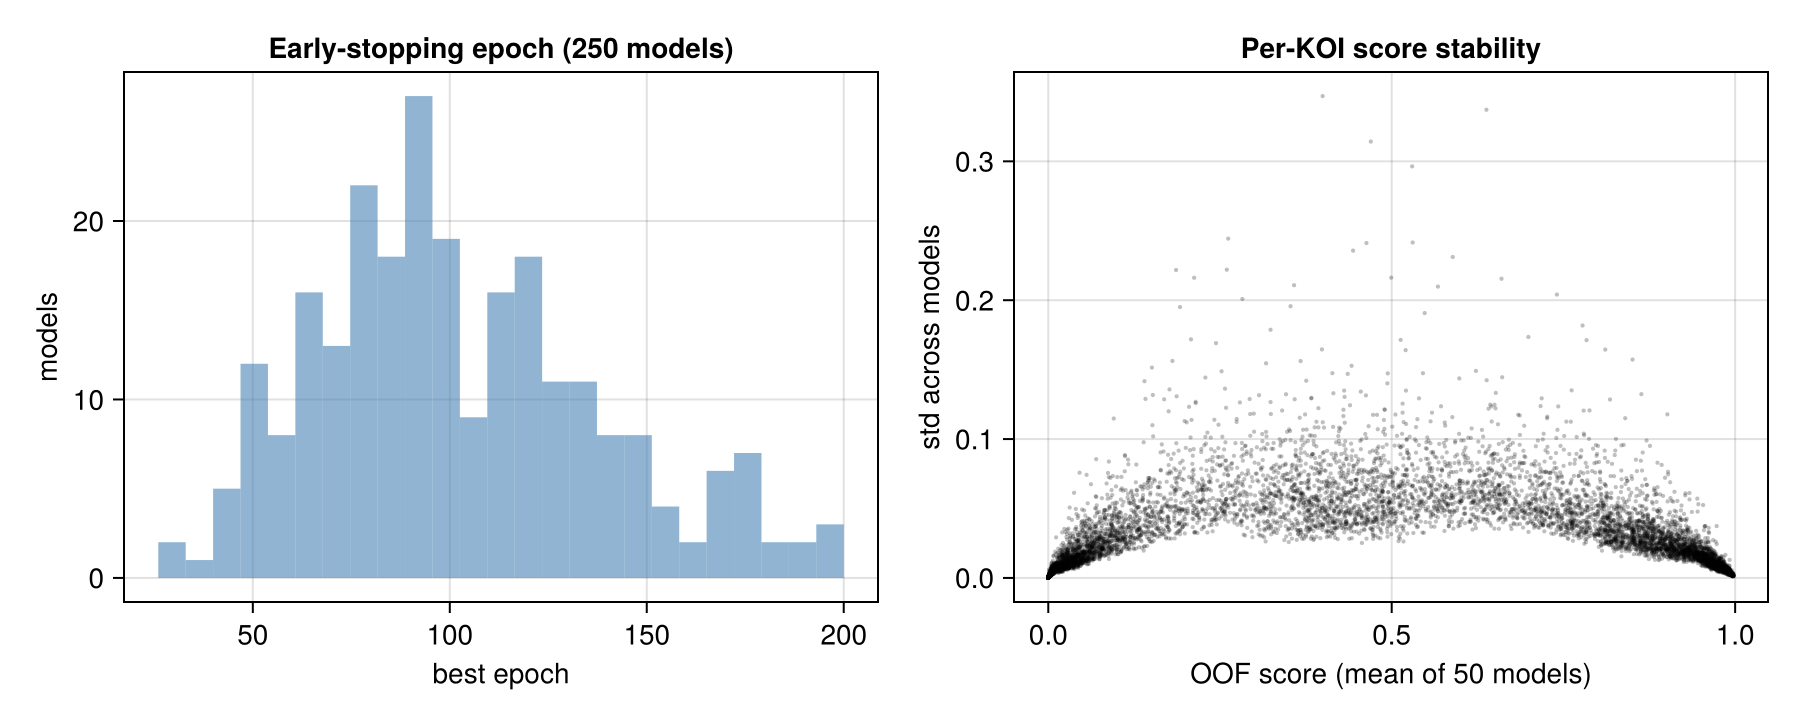

In [8]:
score_sd = vec(std(reshape(cv.oof, nrow(pool), :); dims = 2))     # spread over all 50 models per KOI
fig = Figure(size = (900, 360))
a1 = Axis(fig[1, 1]; xlabel = "best epoch", ylabel = "models", title = "Early-stopping epoch (250 models)")
hist!(a1, cv.results.best_epoch; bins = 25, color = (:steelblue, 0.6))
a2 = Axis(fig[1, 2]; xlabel = "OOF score (mean of 50 models)", ylabel = "std across models", title = "Per-KOI score stability")
scatter!(a2, s_final, score_sd; markersize = 3, color = (:black, 0.25))
savefig("exo101026_stability.png", fig)
println(@sprintf("per-KOI score std: median %.3f, 90th pct %.3f; KOIs whose 0.5 call flips between models: %.1f%%",
                 median(score_sd), quantile(score_sd, 0.9),
                 100 * mean([length(unique(vec(cv.oof[i, :, :]) .>= 0.5)) > 1 for i in 1:nrow(pool)])))
fig

**Reading this:** early stopping lands anywhere from epoch ~30 to 200 (median ~100; a few runs hit the 200 cap, so
the cap could be raised a little). Individual KOI scores wobble by ~0.03 between models, more near 0.5, so 17% of KOIs
flip their hard call in at least one of the 50 models. Use the averaged score for any per-KOI statement.

## 2. Error analysis (out-of-fold scores)
Every pool KOI gets the mean score of 50 models (10 seeds × 5 fold shuffles) that never saw its star. Robovetter
flags, comments and `koi_score` are joined in **for analysis only**.

2×12 DataFrame
 Row │ subset                 n      roc_auc   pr_auc    accuracy  precision  recall    f1        tp     fp     tn     fn
     │ String                 Int64  Float64   Float64   Float64   Float64    Float64   Float64   Int64  Int64  Int64  Int64
─────┼───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ all (CONF+CAND vs FP)   8288  0.925054  0.92177   0.842061   0.840898  0.845544  0.843215   3520    666   3459    643
   2 │ CONFIRMED vs FP         6598  0.96376   0.938088  0.881176   0.779543  0.952285  0.857299   2355    666   3459    118


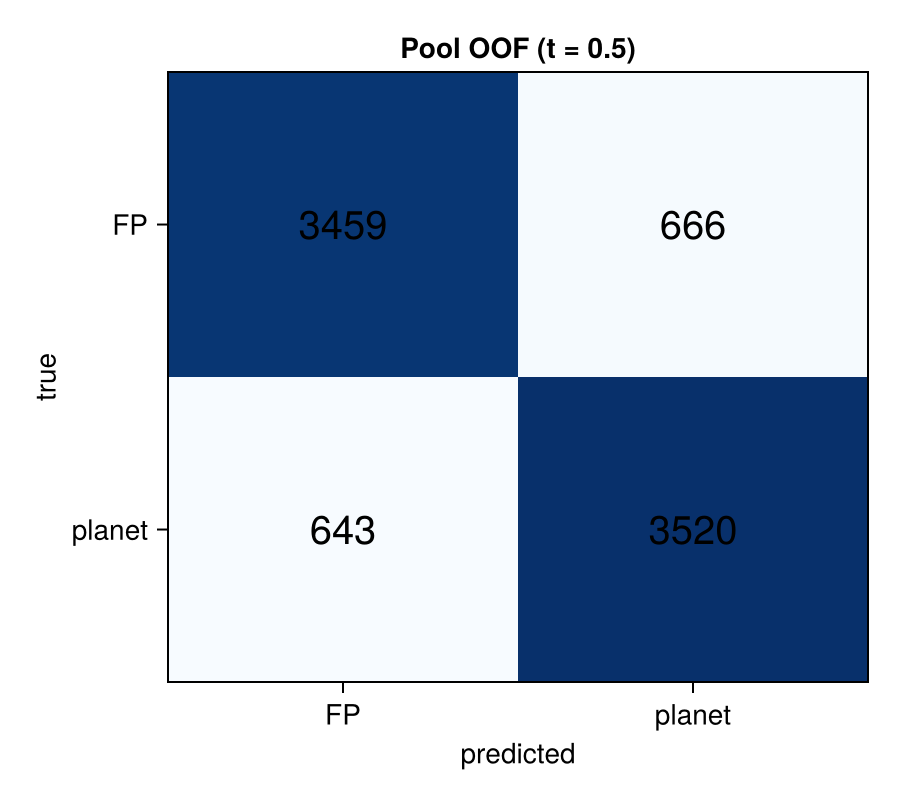

In [9]:
a = with_vetting_info(pool, df_raw, s_final)
println(evaluate_subsets(a, a.score))
fig = plot_confusion(a.label, a.score; title = "Pool OOF")
savefig("exo101026_oof_confusion.png", fig)
fig

### 2.0b Error budget: where the mistakes at threshold 0.5 come from

In [10]:
fp_miss = a[(a.label .== 0) .& (a.score .>= 0.5), :]
pl_miss = a[(a.label .== 1) .& (a.score .< 0.5), :]
pct(x, n) = @sprintf("%4d  (%4.1f%%)", x, 100x / n)
nf, np = nrow(fp_miss), nrow(pl_miss)
println("FALSE POSITIVES called planets: $nf")
println("  in multi-KOI systems (koi_count ≥ 2)       ", pct(sum(fp_miss.koi_count .>= 2), nf))
println("  flagged CO and/or EC (centroid/contam.)    ", pct(sum((fp_miss.koi_fpflag_co .== 1) .| (fp_miss.koi_fpflag_ec .== 1)), nf))
println("  flagged NT (not transit-like)              ", pct(sum(fp_miss.koi_fpflag_nt .== 1), nf))
println("  flagged SS (stellar eclipse)               ", pct(sum(fp_miss.koi_fpflag_ss .== 1), nf))
println("  model SNR < 15                             ", pct(sum(fp_miss.koi_model_snr .< 15), nf))
println("\nPLANETS called false positives: $np")
println("  CANDIDATE                                  ", pct(sum(pl_miss.koi_disposition .== "CANDIDATE"), np))
println("  CONFIRMED                                  ", pct(sum(pl_miss.koi_disposition .== "CONFIRMED"), np))
println("  period < 1.5 d                             ", pct(sum(pl_miss.koi_period .< 1.5), np))
println("  prad > 15 R⊕                               ", pct(sum(pl_miss.koi_prad .> 15), np))
println("  impact > 0.9 (near-grazing)                ", pct(sum(pl_miss.koi_impact .> 0.9), np))
println("  model SNR < 15                             ", pct(sum(pl_miss.koi_model_snr .< 15), np))
println("  koi_count = 1                              ", pct(sum(pl_miss.koi_count .== 1), np))

FALSE POSITIVES called planets: 666
  in multi-KOI systems (koi_count ≥ 2)        116  (17.4%)
  flagged CO and/or EC (centroid/contam.)     383  (57.5%)
  flagged NT (not transit-like)               240  (36.0%)
  flagged SS (stellar eclipse)                146  (21.9%)
  model SNR < 15                              415  (62.3%)

PLANETS called false positives: 643
  CANDIDATE                                   525  (81.6%)
  CONFIRMED                                   118  (18.4%)
  period < 1.5 d                              140  (21.8%)
  prad > 15 R⊕                                122  (19.0%)
  impact > 0.9 (near-grazing)                 140  (21.8%)
  model SNR < 15                              373  (58.0%)
  koi_count = 1                               603  (93.8%)


In [11]:
# KOIs with no robovetter koi_score: who are they, and how does the model do on them?
nos = ismissing.(a.koi_score)
println(@sprintf("no koi_score: %d KOIs, AUC %.4f   |   with koi_score: %d KOIs, AUC %.4f",
                 sum(nos), fast_auc(a.label[nos], a.score[nos]), sum(.!nos), fast_auc(a.label[.!nos], a.score[.!nos])))
println("dispositions without koi_score: ", countmap(a.koi_disposition[nos]))
println("koi_pdisposition without koi_score: ", countmap(a.koi_pdisposition[nos]))
println(@sprintf("median model SNR  no score %.1f vs with score %.1f; median prad %.2f vs %.2f",
                 median(a.koi_model_snr[nos]), median(a.koi_model_snr[.!nos]), median(a.koi_prad[nos]), median(a.koi_prad[.!nos])))

no koi_score: 1089 KOIs, AUC 0.6519   |   with koi_score: 7199 KOIs, AUC 0.9475
dispositions without koi_score: Dict{DataStrings.DataString, Int64}("CANDIDATE" => 455, "FALSE POSITIVE" => 620, "CONFIRMED" => 14)
koi_pdisposition without koi_score: Dict{Union{Missing, DataStrings.DataString}, Int64}("CANDIDATE" => 468, "FALSE POSITIVE" => 621)
median model SNR  no score 8.9 vs with score 27.3; median prad 2.03 vs 2.47


**Why no `koi_score`?** All of them are *supplemental* KOIs (`koi_disp_prov = q1_q17_dr25_sup_koi`) whose transit
signal (TCE) came from an older pipeline run (Q1–Q16 or DR24), or from no TCE at all, and was **not re-detected by the
final, uniform DR25 run**, so the DR25 robovetter never scored them. Their parameters come from older fits and they
sit near the detection limit. Breakdown by TCE delivery:

In [12]:
a.tce_source = String.(coalesce.(a.koi_tce_delivname, "none (no TCE)"))
prov = combine(groupby(a, :tce_source), nrow => :n, :label => mean => :planet_frac,
               [:label, :score] => ((y, s) -> fast_auc(y, s)) => :roc_auc,
               [:label, :score] => ((y, s) -> mean((s .>= 0.5) .!= (y .== 1))) => :error_rate,
               [:label, :score] => ((y, s) -> sum((s .>= 0.5) .!= (y .== 1))) => :errors,
               :koi_model_snr => median => :median_snr)
prov.share_of_all_errors = prov.errors ./ sum(prov.errors)
sort!(prov, :n; rev = true)

Row,tce_source,n,planet_frac,roc_auc,error_rate,errors,median_snr,share_of_all_errors
,String,Int64,Float64,Float64,Float64,Int64,Float64,Float64
1,q1_q17_dr25_tce,7199,0.513127,0.947545,0.121684,876,27.3,0.669213
2,q1_q16_tce,570,0.529825,0.55833,0.475439,271,7.9,0.207028
3,q1_q17_dr24_tce,296,0.391892,0.781322,0.300676,89,10.65,0.0679908
4,none (no TCE),223,0.2287,0.740424,0.327354,73,10.2,0.0557678


**Reading this:** the DR25-detected KOIs are where the model works (AUC 0.948). The 570 KOIs that only the older
Q1–Q16 run detected are essentially **random (AUC 0.56, 48% error rate)** and alone produce 21% of all errors; DR24-only
and no-TCE KOIs are poor too (0.78, 0.74). Their catalog parameters come from older fits at SNR ≈ 8–11, so they
probably carry less information. Whether to keep them in training,
score them separately, or drop them is a scoping decision for later (see conclusions).

### 2.1 Missed false positives by robovetter flag
`missed_frac` = fraction of that group the model scores ≥ 0.5 (calls a planet). Flags overlap: "has X" groups
double count, "only X+Y" groups are exact combinations.

In [13]:
fp_flag_table(a)

Row,group,n,median_score,missed_frac
,String,Int64,Float64,Float64
1,all FPs,4125,0.0890549,0.161455
2,has NT (not transit-like),1197,0.324985,0.200501
3,has SS (stellar eclipse),1979,0.0213155,0.0737746
4,has CO (centroid offset),1685,0.133528,0.207122
5,has EC (ephemeris match),1022,0.0925874,0.143836
6,only SS,1307,0.00521045,0.0451415
7,only NT,849,0.392868,0.246172
8,only CO,464,0.348508,0.37931
9,only CO+EC,339,0.150604,0.19764


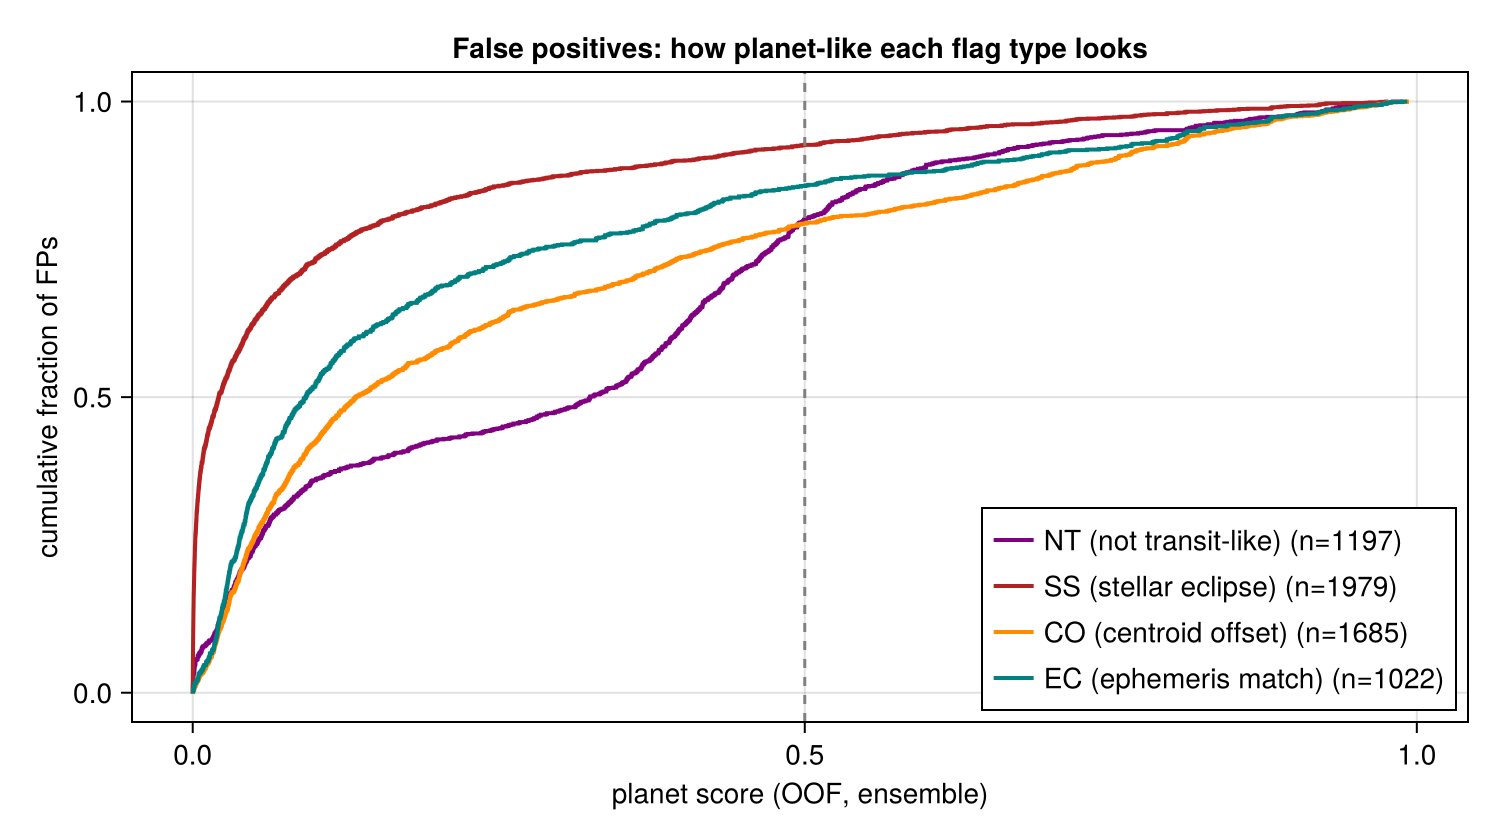

In [14]:
fig = plot_score_by_flag(a)
savefig("exo101026_fp_by_flag.png", fig)
fig

**Reading this:** stellar-eclipse FPs (SS) sit near 0: big, deep, V-shaped, grazing signals are easy from catalog
parameters. The hard groups are **CO-only** (centroid offset: the signal comes from a nearby star; 38% missed),
**NT-only** (not transit-like: systematics or variability; 25% missed, with a broad bump of scores around 0.3–0.5), and
**EC-only** (ephemeris match: contamination from another known source; 23% missed). FPs flagged by several tests are
easier, presumably because multiple problems leave multiple traces in the parameters.

### 2.2 Robovetter comment codes
Codes carried by at least 40 FPs in the pool, sorted by how often the model misses them.

In [15]:
comment_token_table(a; min_n = 40)

Row,token,n,median_score,missed_frac
,String,Int64,Float64,Float64
1,CLEAR_APO,56,0.374497,0.428571
2,INDIV_TRANS_SKYE,47,0.435077,0.404255
3,NO_COMMENT,41,0.243437,0.292683
4,MOD_NONUNIQ_ALT,184,0.312919,0.26087
5,CENT_RESOLVED_OFFSET,921,0.13652,0.216069
6,LPP_ALT_TOO_HIGH,43,0.0632656,0.209302
7,CENT_UNRESOLVED_OFFSET,323,0.134056,0.19195
8,HALO_GHOST,772,0.111271,0.189119
9,EYEBALL,58,0.116034,0.172414


**Reading this:** every eclipsing-binary signature is caught ≥ 91% of the time: odd/even depth (`*_ODDEVEN_*`),
`DEEP_V_SHAPED`, `SWEET_EB` and `PLANET_IN_STAR` at ≥ 97%, secondary eclipses (`MOD_SEC_*`, `HAS_SEC_TCE`) at 91–93%. The most-missed codes need information the table
does not have: aperture/pixel diagnostics (`CLEAR_APO`, `HALO_GHOST`, `CENT_*_OFFSET`), per-transit inspection
(`INDIV_TRANS_SKYE`: individual transits on known bad "sky" columns), and alternative-detrending uniqueness tests
(`MOD_NONUNIQ_ALT`). These are exactly what light curves and centroid time series (Phase 2) would provide.

### 2.3 Errors across parameter space
Quantile bins of each raw feature. Red = FPs called planets, blue = planets called FPs, green = ROC-AUC within the
bin (how well the model separates KOIs that look alike in that parameter).

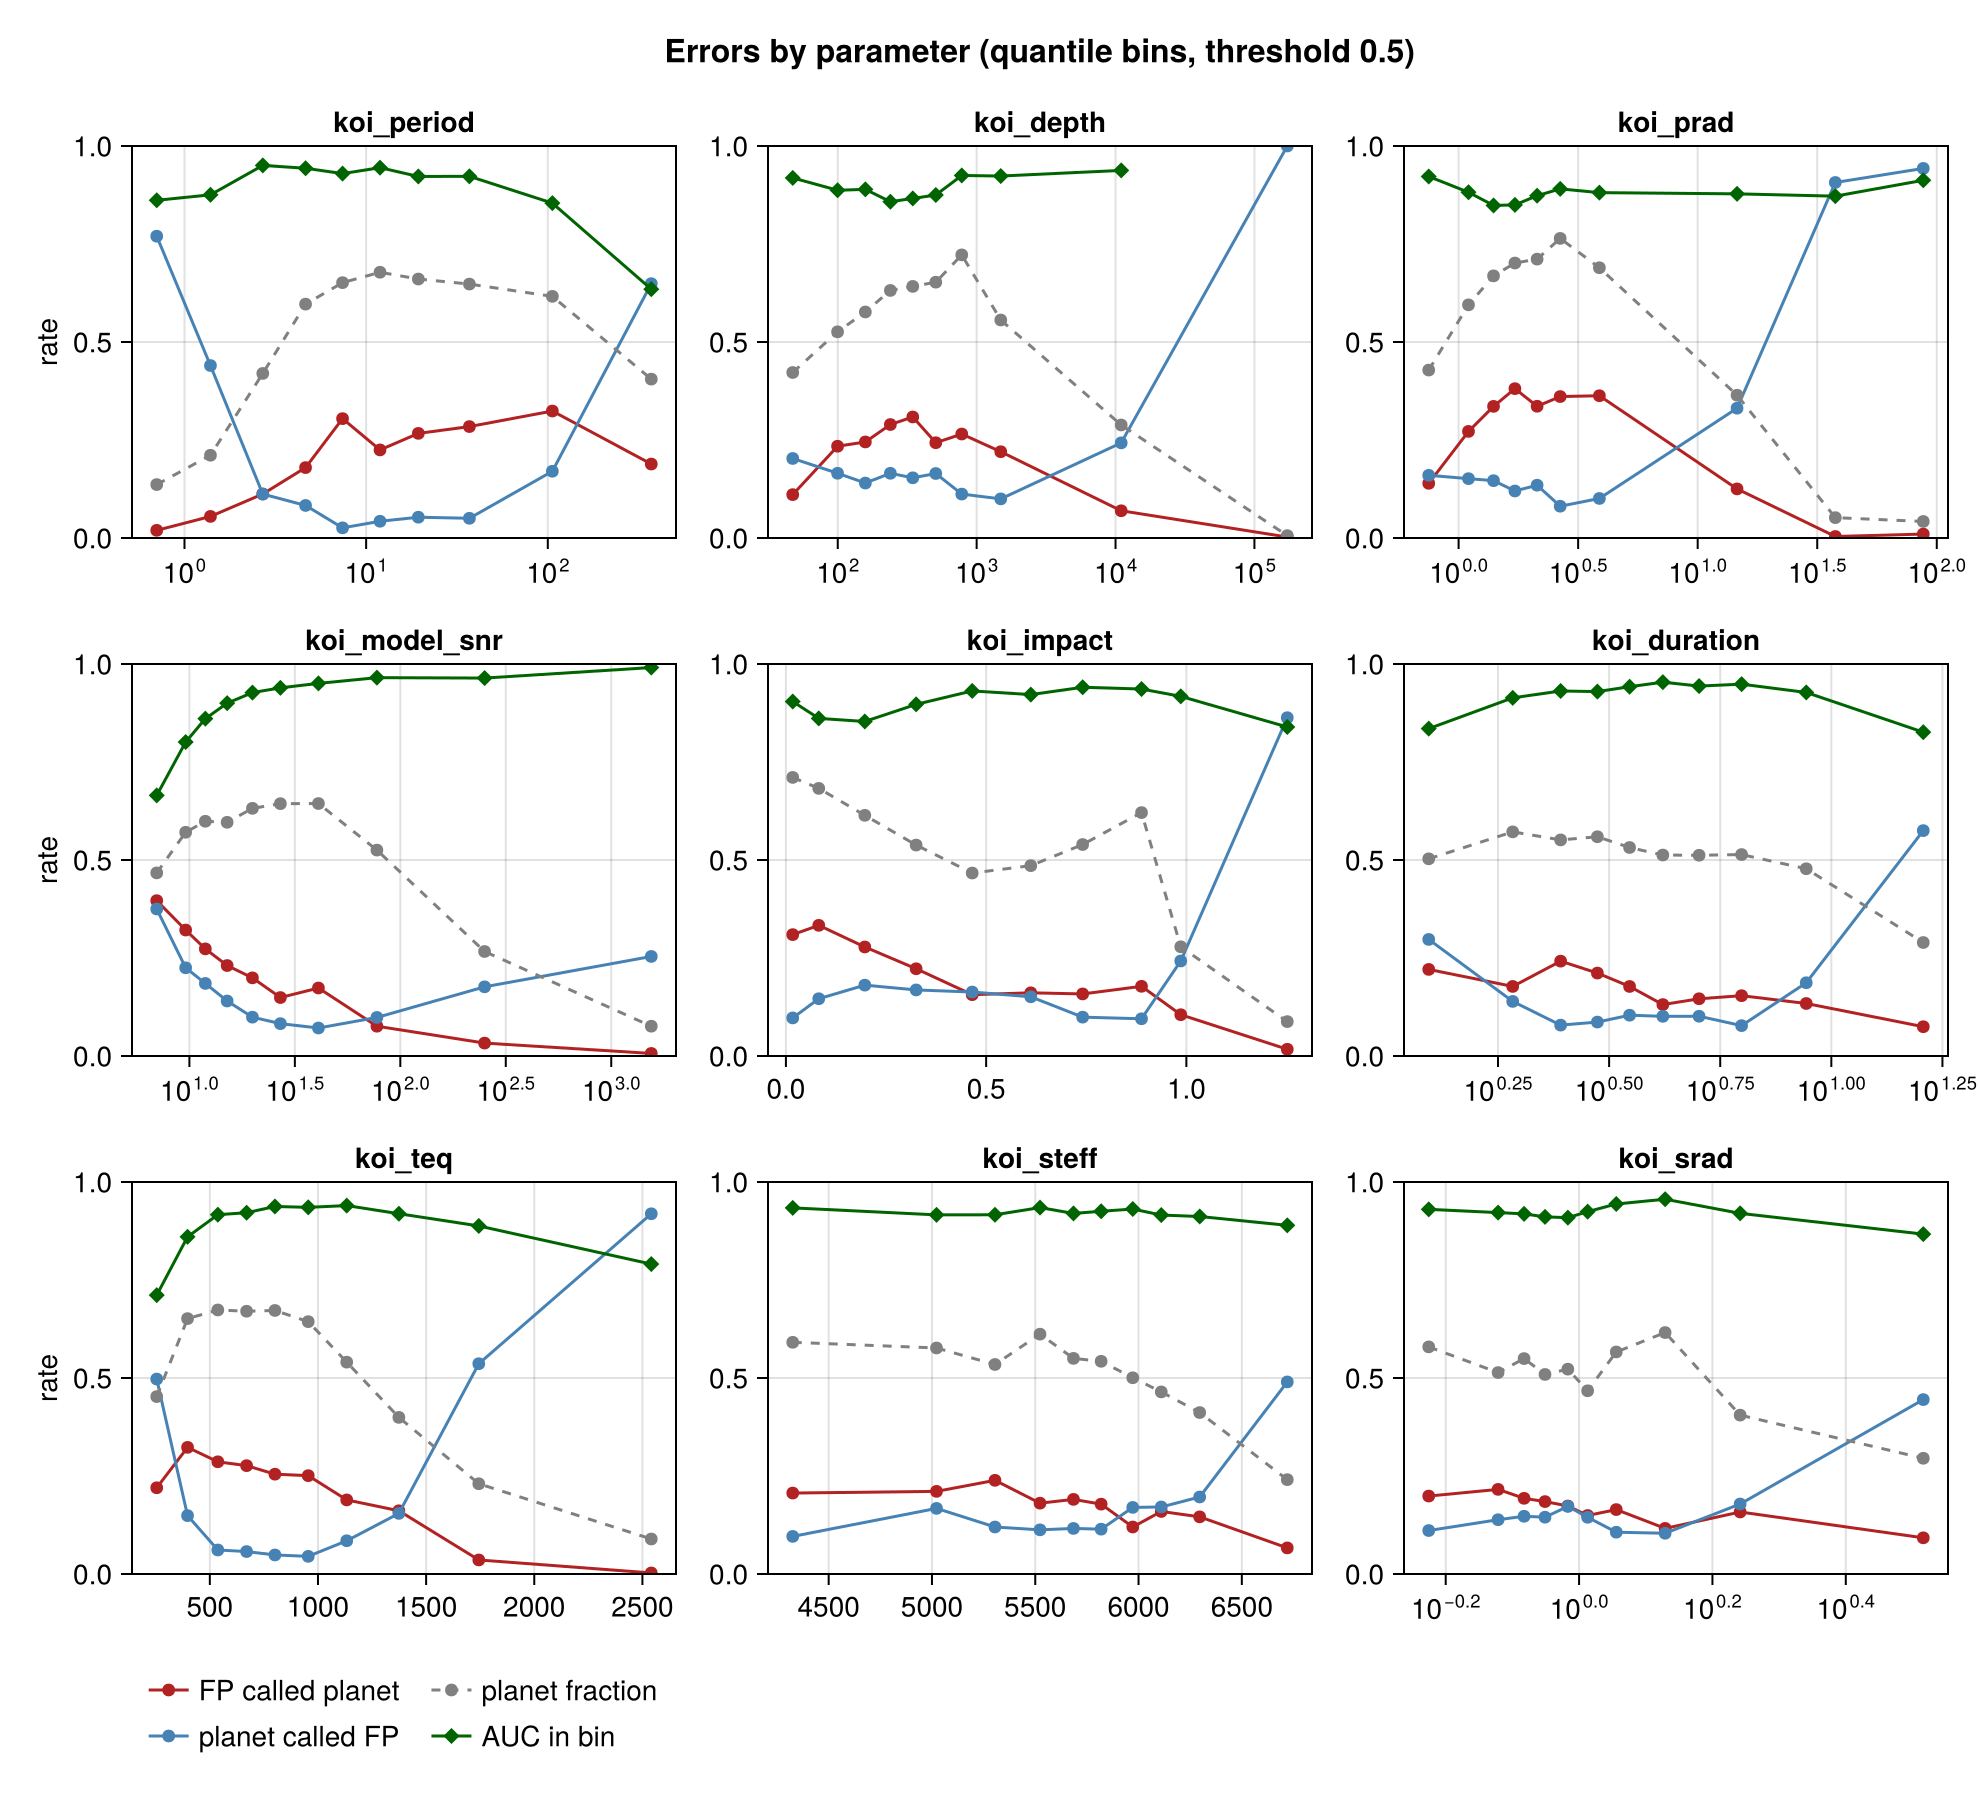

In [16]:
fig = plot_binned_errors(a, [:koi_period, :koi_depth, :koi_prad, :koi_model_snr, :koi_impact, :koi_duration,
                             :koi_teq, :koi_steff, :koi_srad];
                         logx = [:koi_period, :koi_depth, :koi_prad, :koi_model_snr, :koi_srad, :koi_duration])
savefig("exo101026_binned_errors.png", fig)
fig

**Reading this:**
- **SNR is the master variable**: within-bin AUC climbs from ~0.67 at SNR ≈ 7 to ~0.95 above SNR ≈ 30. Most errors
  of both kinds are low-SNR KOIs (62% of missed FPs, 58% of missed planets have SNR < 15).
- **Ultra-short periods (< 1.5 d)**: most real planets there are called FPs. FPs dominate that period range, so the
  model learned "short period → FP".
- **Long periods (> 100 d)**: few transits, within-bin AUC drops to ~0.63.
- **Large radii / deep transits / impact > 1**: "planets" there are almost all called FPs. These are mostly CANDIDATEs
  with R > 15 R⊕, which are physically more likely to be stars than planets (see 2.4).
- **Stellar parameters** (Teff, R★) barely matter except at the hot / large-star end.

In [17]:
# Multiplicity (koi_count is discrete, so group directly)
combine(groupby(a, :koi_count), nrow => :n, :label => mean => :planet_frac,
        [:label, :score] => ((y, s) -> mean(s[y .== 0] .>= 0.5)) => :fp_miss,
        [:label, :score] => ((y, s) -> mean(s[y .== 1] .< 0.5)) => :planet_miss)

Row,koi_count,n,planet_frac,fp_miss,planet_miss
,Int64,Int64,Float64,Float64,Float64
1,1,6288,0.386132,0.142487,0.248353
2,2,1142,0.805604,0.369369,0.0358696
3,3,489,0.961145,0.736842,0.00638298
4,4,228,0.938596,0.714286,0.0186916
5,5,115,0.921739,1.0,0.0
6,6,12,1.0,NaN,0.0
7,7,14,0.928571,1.0,0.0


**Reading this:** multiplicity is a real astrophysical prior (Lissauer et al. 2012: multis are mostly real), but the
model leans on it hard. Nearly every FP in a 3+ KOI system is called a planet, and almost all missed planets are
singles. A `koi_count` ablation (step 4) will show how much of the AUC this one feature carries.

### 2.4 CONFIRMED vs CANDIDATE
Both are labeled 1 in training. If CANDIDATE labels contain hidden false positives, CANDIDATE scores should sit lower
and have a tail toward 0.

3×5 DataFrame
 Row │ koi_disposition  n      median     p10         frac_below_half
     │ DataString       Int64  Float64    Float64     Float64
─────┼────────────────────────────────────────────────────────────────
   1 │ CANDIDATE         1690  0.712617   0.307569          0.310651
   2 │ FALSE POSITIVE    4125  0.0890549  0.00108849        0.838545
   3 │ CONFIRMED         2473  0.933218   0.667181          0.0477153


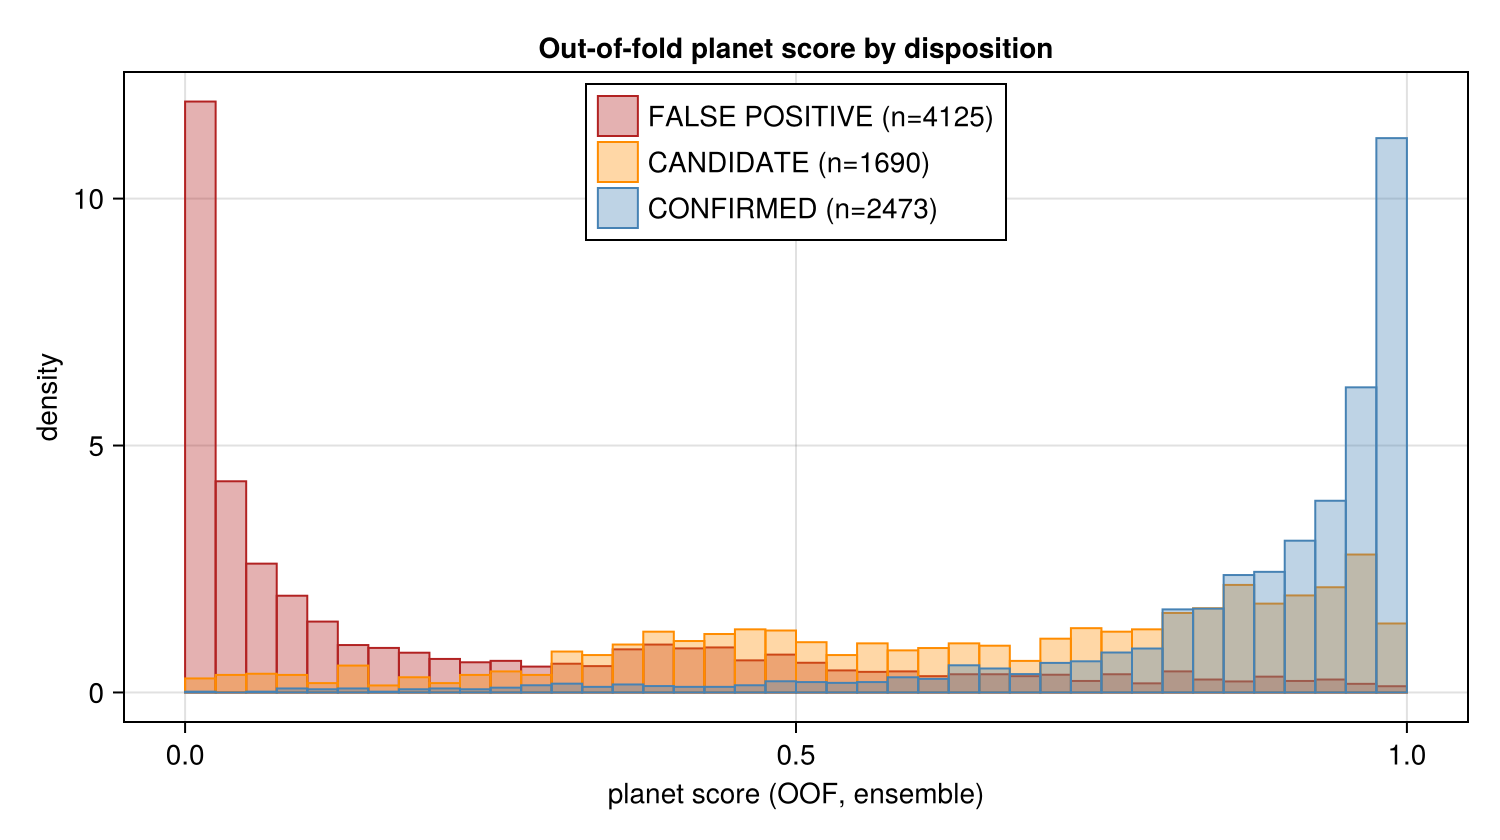

In [18]:
fig = plot_score_by_disposition(a)
savefig("exo101026_score_by_disposition.png", fig)
println(combine(groupby(a, :koi_disposition), nrow => :n, :score => median => :median,
                :score => (s -> quantile(s, 0.1)) => :p10, :score => (s -> mean(s .< 0.5)) => :frac_below_half))
fig

In [19]:
show_cols = [:kepoi_name, :koi_disposition, :score, :koi_score, :koi_period, :koi_depth, :koi_prad, :koi_impact,
             :koi_model_snr, :koi_count]
println("Lowest-scored CANDIDATEs (model thinks most FP-like):")
println(first(sort(a[a.koi_disposition .== "CANDIDATE", show_cols], :score), 15))
println("\nLowest-scored CONFIRMED planets (model's worst misses on confirmed planets):")
println(first(sort(a[a.koi_disposition .== "CONFIRMED", show_cols], :score), 15))

Lowest-scored CANDIDATEs (model thinks most FP-like):
15×10 DataFrame
 Row │ kepoi_name  koi_disposition  score       koi_score    koi_period  koi_depth  koi_prad  koi_impact  koi_model_snr  koi_count
     │ DataString  DataString       Float64     Float64?     Float64     Float64    Float64   Float64     Float64        Int64
─────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ K02671.01   CANDIDATE        0.00182961        0.0     21.4764     348130.0     59.5       0.006           124.8          2
   2 │ K05156.01   CANDIDATE        0.0032255   missing        1.68025     51633.0     30.88      0.7314          178.7          1
   3 │ K00820.01   CANDIDATE        0.00359985        0.0      4.6409       2450.6     30.09      1.28            296.9          1
   4 │ K07360.01   CANDIDATE        0.0053049   missing        4.09536       226.8      7.76      1.0194           60.2          1
   5 │ K06705.01

In [20]:
println("Highest-scored FALSE POSITIVEs (most planet-like FPs):")
fp_top = first(sort(a[a.label .== 0, :], :score; rev = true), 15)
println(fp_top[:, [:kepoi_name, :score, :flag_pattern, :koi_period, :koi_depth, :koi_prad, :koi_impact, :koi_model_snr, :koi_count]])
println()
for r in eachrow(fp_top[1:8, :])
    println(rpad(r.kepoi_name, 12), join(r.comment_tokens, ", "))
end

Highest-scored FALSE POSITIVEs (most planet-like FPs):
15×9 DataFrame
 Row │ kepoi_name  score     flag_pattern  koi_period  koi_depth  koi_prad  koi_impact  koi_model_snr  koi_count
     │ DataString  Float64   String        Float64     Float64    Float64   Float64     Float64        Int64
─────┼───────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ K01196.01   0.992203  CO+EC            3.98217      381.3      3.32      0.775            27.1          3
   2 │ K00989.04   0.992007  CO               4.08029     1128.4      2.92      0.2428           43.1          4
   3 │ K04288.03   0.988514  NT               4.32744       22.0      0.58      0.2789            8.0          4
   4 │ K01803.02   0.98826   EC              12.7203       283.6      1.37      0.805            12.7          3
   5 │ K01437.02   0.98296   CO               9.27989      164.3      1.29      0.579             8.6          3
   6 │ K04365.02   0.98032   

**Reading this:**
- **Lowest CANDIDATEs** come in two kinds. Most look like stellar companions: radii of 25–700 R⊕, depths up to 35%,
  impact > 1 (grazing), several with `koi_score = 0` so the robovetter doubts them too. Here the model acts as a
  label-noise detector, and these "errors" are arguably correct. The others are small (0.2–1.5 R⊕) ultra-short-period
  signals (P < 2 d): the USP blind spot again.
- **Lowest CONFIRMED planets** fall into two groups: a few large/grazing ones (e.g. K01450.01, 59 R⊕, b = 1.23) and many
  **ultra-short-period small planets** (P < 1.5 d, R ≈ 1–2.7 R⊕), a real population sitting where FPs dominate.
- **Most planet-like FPs** are small (1–3.5 R⊕), moderate-SNR signals in **multi-KOI systems**, flagged for centroid
  offsets, contamination or not-transit-like behaviour. They are indistinguishable from planets in catalog parameters.

### 2.5 Comparison with the robovetter's `koi_score`
`koi_score` comes out of the same vetting that set many dispositions, so its AUC against the labels is partly
circular. This is a sanity check on *where* the two disagree, not a benchmark.

(n = 7199, n_missing = 1089, spearman = 0.7507214058741263, agree_frac = 0.8630365328517849, auc_model = 0.9475448871478366, auc_koi_score = 0.9702549996254094)


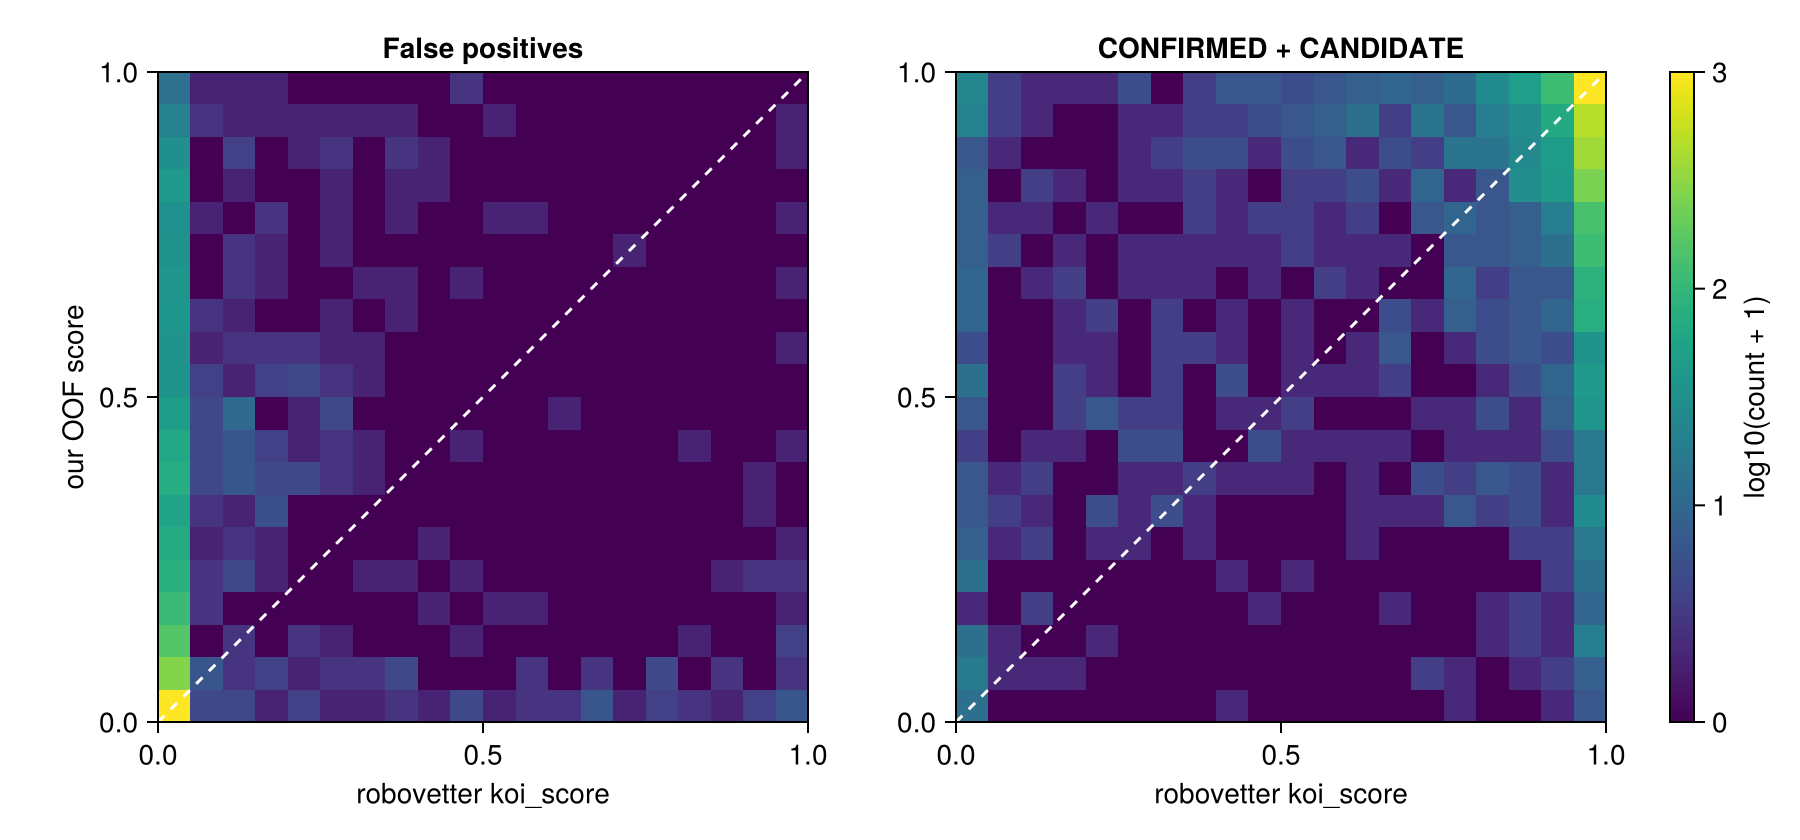

In [21]:
ks_sum, b = koi_score_comparison(a)
println(ks_sum)
fig = plot_koi_score_comparison(b)
savefig("exo101026_vs_koi_score.png", fig)
fig

**Reading this:** on the 7,199 KOIs it scores, the robovetter reaches AUC 0.970 vs our 0.948. That gap is partly
circular, since `koi_score` helped set those labels, but it is also the expected gain from pixel-level and light-curve
tests. The two scores rank KOIs similarly (Spearman 0.75) and agree on 86% of hard calls. The bright left column in
both panels: many KOIs got `koi_score ≈ 0` while our model is unsure or says planet. Among planets these are
KOIs the DR25 robovetter scored near 0 but whose cumulative disposition is still CANDIDATE/CONFIRMED (presumably
from other vetting or follow-up). Among FPs they are the centroid / not-transit-like cases from 2.1–2.2.

In [22]:
# Save every pool KOI's OOF score so later steps can track the same hard cases
oof_tbl = a[:, [:kepoi_name, :kepid, :koi_disposition, :label, :score, :flag_pattern, :koi_score]]
oof_tbl.score_sd = score_sd
CSV.write(joinpath(CV_DIR, "oof_baseline_r5s10.csv"), oof_tbl)
println("wrote ", joinpath(CV_DIR, "oof_baseline_r5s10.csv"))

wrote C:\JuliaProjects\Exoplanet vetting\sweeps\results\oof_baseline_r5s10.csv


In [23]:
# Disagreements by disposition: model says planet but robovetter says FP-like, and vice versa
b.model_planet = b.score .>= 0.5
b.rv_planet = b.koi_score .>= 0.5
combine(groupby(b, :koi_disposition), nrow => :n,
        [:model_planet, :rv_planet] => ((m, r) -> mean(m .& .!r)) => :model_yes_rv_no,
        [:model_planet, :rv_planet] => ((m, r) -> mean(.!m .& r)) => :model_no_rv_yes,
        [:model_planet, :rv_planet] => ((m, r) -> mean(m .== r)) => :agree)

Row,koi_disposition,n,model_yes_rv_no,model_no_rv_yes,agree
,DataStri…,Int64,Float64,Float64,Float64
1,CANDIDATE,1235,0.08583,0.14251,0.77166
2,FALSE POSITIVE,3505,0.128959,0.0239658,0.847076
3,CONFIRMED,2459,0.0231802,0.0451403,0.93168


## 3. Robustness checks
### 3.1 Noise thresholds for other metrics
The same null test as 1.4 (5-seed vs 5-seed ensembles, identical folds) and a star bootstrap, for each metric a later
comparison might use. `null_95` is the training-noise bar; `boot_halfwidth` is the 95% sampling uncertainty of the
metric itself for this pool. Log-loss: lower is better.

In [24]:
conf = a.koi_disposition .!= "CANDIDATE"
cv_conf = merge(cv, (oof = cv.oof[conf, :, :], folds = cv.folds[conf, :], kepoi = cv.kepoi[conf]))
pool_conf = pool[conf, :]
prauc(y, p) = au_prcurve(Int.(y), p)
metric_specs = [("ROC-AUC", fast_auc, cv, pool), ("PR-AUC", prauc, cv, pool), ("log-loss", logloss, cv, pool),
                ("ROC-AUC, CONFIRMED vs FP", fast_auc, cv_conf, pool_conf),
                ("PR-AUC, CONFIRMED vs FP", prauc, cv_conf, pool_conf)]
thr = map(metric_specs) do (name, m, c, p)
    nd = null_differences(c, p; n = 300, metric = m)
    bs_m = star_bootstrap(p.label, oof_scores(c), p.kepid; B = 500, metric = m)
    (metric = name, baseline = m(p.label, oof_scores(c)), null_std = std(nd), null_95 = quantile(abs.(nd), 0.95),
     boot_lo = bs_m.lo, boot_hi = bs_m.hi, boot_halfwidth = (bs_m.hi - bs_m.lo) / 2)
end |> DataFrame

Row,metric,baseline,null_std,null_95,boot_lo,boot_hi,boot_halfwidth
,String,Float64,Float64,Float64,Float64,Float64,Float64
1,ROC-AUC,0.925054,0.000263413,0.000475473,0.920074,0.930598,0.005262
2,PR-AUC,0.92177,0.000332252,0.000637499,0.91384,0.929364,0.00776152
3,log-loss,0.346302,0.000610017,0.00107148,0.33386,0.357892,0.0120161
4,"ROC-AUC, CONFIRMED vs FP",0.96376,0.000253282,0.000483084,0.959207,0.967981,0.00438734
5,"PR-AUC, CONFIRMED vs FP",0.938088,0.000582654,0.00113431,0.928714,0.946582,0.00893398


### 3.2 Are the error findings stable?
Each of the 5 fold shuffles gives an *independent* set of OOF predictions (different folds, so different training
sets per KOI). Recomputing the headline error numbers per shuffle shows whether they depend on one lucky partition.
`wilson95` is the binomial 95% interval for the 50-model ensemble's rate (sampling uncertainty from finite group size).

In [25]:
function wilson(k, n; z = 1.96)
    p = k / n; d = 1 + z^2 / n
    c = (p + z^2 / (2n)) / d; h = z * sqrt(p * (1 - p) / n + z^2 / (4n^2)) / d
    return (c - h, c + h)
end
fp = a.label .== 0
groups = [("FP missed: SS only",   fp .& (a.flag_pattern .== "SS")),
          ("FP missed: CO only",   fp .& (a.flag_pattern .== "CO")),
          ("FP missed: NT only",   fp .& (a.flag_pattern .== "NT")),
          ("FP missed: EC only",   fp .& (a.flag_pattern .== "EC")),
          ("FP missed: koi_count ≥ 3", fp .& (a.koi_count .>= 3)),
          ("FP missed: koi_count = 1", fp .& (a.koi_count .== 1)),
          ("CONFIRMED called FP",  a.koi_disposition .== "CONFIRMED"),
          ("CANDIDATE called FP",  a.koi_disposition .== "CANDIDATE"),
          ("planet called FP: P < 1.5 d", (a.label .== 1) .& (a.koi_period .< 1.5))]
err_rate(s, m, isfp) = isfp ? mean(s[m] .>= 0.5) : mean(s[m] .< 0.5)
stab = map(groups) do (name, m)
    isfp = startswith(name, "FP")
    per_rep = [err_rate(vec(mean(cv.oof[:, r, :]; dims = 2)), m, isfp) for r in 1:R]
    k = isfp ? sum(a.score[m] .>= 0.5) : sum(a.score[m] .< 0.5)
    lo, hi = wilson(k, sum(m))
    (group = name, n = sum(m), ensemble = k / sum(m), per_shuffle_min = minimum(per_rep),
     per_shuffle_max = maximum(per_rep), wilson95_lo = lo, wilson95_hi = hi)
end |> DataFrame
src_auc = [(src, [fast_auc(a.label[a.tce_source .== src], vec(mean(cv.oof[a.tce_source .== src, r, :]; dims = 2))) for r in 1:R])
           for src in ("q1_q17_dr25_tce", "q1_q16_tce")]
for (src, v) in src_auc
    println(rpad(src, 18), "AUC per fold shuffle: ", round.(v; digits = 3))
end
stab

q1_q17_dr25_tce   AUC per fold shuffle: [0.947, 0.947, 0.947, 0.946, 0.947]
q1_q16_tce        AUC per fold shuffle: [0.543, 0.559, 0.564, 0.563, 0.556]


Row,group,n,ensemble,per_shuffle_min,per_shuffle_max,wilson95_lo,wilson95_hi
,String,Int64,Float64,Float64,Float64,Float64,Float64
1,FP missed: SS only,1307,0.0451415,0.0443764,0.0459067,0.0351565,0.0577926
2,FP missed: CO only,464,0.37931,0.372845,0.398707,0.336322,0.424281
3,FP missed: NT only,849,0.246172,0.248528,0.275618,0.218381,0.27625
4,FP missed: EC only,111,0.234234,0.216216,0.234234,0.165156,0.321093
5,FP missed: koi_count ≥ 3,43,0.790698,0.767442,0.790698,0.647941,0.885773
6,FP missed: koi_count = 1,3860,0.142487,0.143005,0.151295,0.131815,0.15387
7,CONFIRMED called FP,2473,0.0477153,0.0460979,0.0521634,0.0399926,0.0568411
8,CANDIDATE called FP,1690,0.310651,0.299408,0.311243,0.289038,0.333123
9,planet called FP: P < 1.5 d,201,0.696517,0.666667,0.681592,0.629762,0.755902


### 3.3 Do the findings survive on DR25 KOIs alone?
Supplemental KOIs are hard *and* differ in composition, so they could distort the flag, multiplicity and parameter
results. Repeat the key tables on the 7,199 DR25-detected KOIs only (same OOF scores, no retraining).

In [26]:
a25 = a[a.tce_source .== "q1_q17_dr25_tce", :]
bs25 = star_bootstrap(a25.label, a25.score, a25.kepid; B = 2000)
println(@sprintf("DR25 KOIs: n = %d, ROC-AUC %.4f (95%% CI %.4f–%.4f)", nrow(a25), fast_auc(a25.label, a25.score), bs25.lo, bs25.hi))
println(evaluate_subsets(a25, a25.score))
println()
println(first(fp_flag_table(a25), 12))
println()
println(combine(groupby(a25, :koi_count), nrow => :n, :label => mean => :planet_frac,
                [:label, :score] => ((y, s) -> mean(s[y .== 0] .>= 0.5)) => :fp_miss,
                [:label, :score] => ((y, s) -> mean(s[y .== 1] .< 0.5)) => :planet_miss))

DR25 KOIs: n = 7199, ROC-AUC 0.9475 (95% CI 0.9426–0.9524)
2×12 DataFrame
 Row │ subset                 n      roc_auc   pr_auc    accuracy  precision  recall    f1        tp     fp     tn     fn
     │ String                 Int64  Float64   Float64   Float64   Float64    Float64   Float64   Int64  Int64  Int64  Int64
─────┼───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ all (CONF+CAND vs FP)   7199  0.947545  0.946877  0.878316   0.873938  0.891446  0.882605   3293    475   3030    401
   2 │ CONFIRMED vs FP         5964  0.969659  0.954489  0.90057    0.831321  0.952013  0.887583   2341    475   3030    118

12×4 DataFrame
 Row │ group                      n      median_score  missed_frac
     │ String                     Int64  Float64       Float64
─────┼─────────────────────────────────────────────────────────────
   1 │ all FPs                     3505    0.0632411     0.135521
   2 │ has NT (not tran

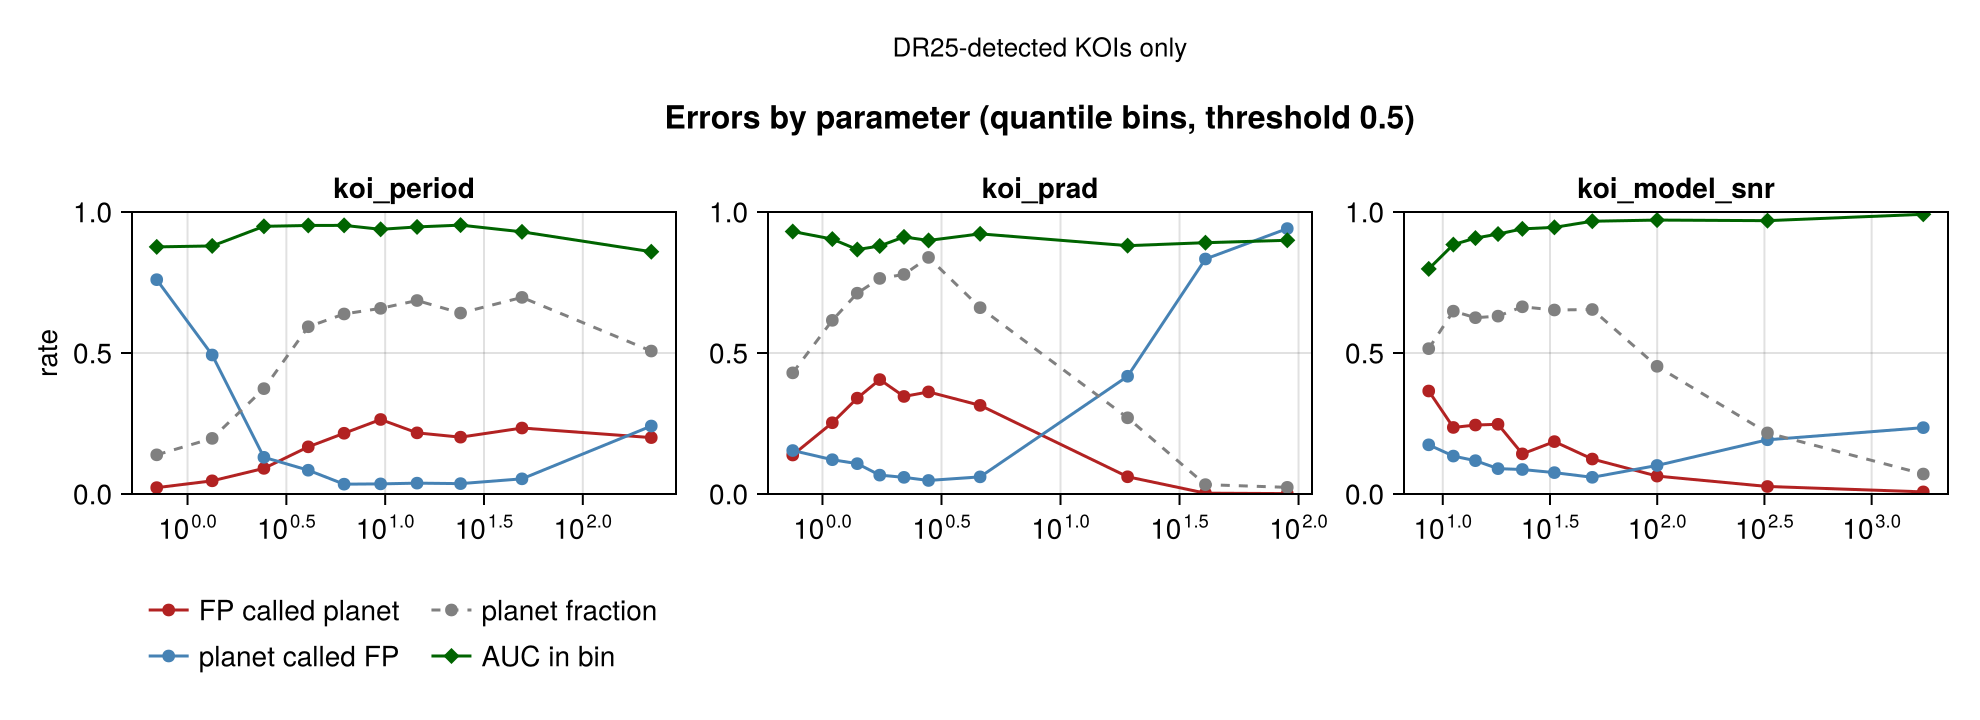

In [27]:
fig = plot_binned_errors(a25, [:koi_period, :koi_prad, :koi_model_snr]; ncols = 3,
                         logx = [:koi_period, :koi_prad, :koi_model_snr])
Label(fig[-1, :], "DR25-detected KOIs only"; fontsize = 13)
savefig("exo101026_binned_errors_dr25.png", fig)
fig

**Reading 3.1–3.3:**
- **Thresholds for later comparisons** (two runs of the same config, 95%): ROC-AUC 0.0005, PR-AUC 0.0006,
  log-loss 0.0011, CONFIRMED-vs-FP ROC-AUC 0.0005, CONFIRMED-vs-FP PR-AUC 0.0011. The metrics themselves carry
  ±0.004–0.012 sampling uncertainty for this pool, which is why paired comparisons are needed.
- **The error findings are not partition luck.** Every headline rate moves by ≤ 0.03 across the 5 independent fold
  shuffles. Q1–Q16 KOIs score AUC 0.54–0.56 in every shuffle; DR25 KOIs 0.946–0.947.
- **Ultra-short periods are a real blind spot:** 70% of planets with P < 1.5 d (n = 201) are called FPs.
- **On DR25 KOIs alone** (AUC 0.948, 95% CI 0.943–0.952; CONFIRMED vs FP 0.970):
  - the centroid-offset blind spot persists (36% of CO-only FPs missed);
  - the multiplicity effect persists (FPs with 3+ KOIs: 43–100% missed by count; planet misses almost all singles);
  - EB-type FPs stay easy (4.5% missed);
  - the "not transit-like" problem shrinks (NT-only missed 18% vs 25%), and the long-period and low-SNR weak spots
    mostly disappear (within-bin AUC ≈ 0.86 at P > 100 d vs 0.63, ≈ 0.80 at the lowest SNR vs 0.67). Much of those
    came from the supplemental KOIs.

## 4. Conclusions and what they mean for steps 3–5

**Noise floor (step 1).** Always compare configs with star-grouped repeated CV on the same folds (`cv_run` with
`repeats = 5`, `seeds = 1:5`, default `fold_seed0`; ~8 min per config), then `compare_cv` against
`cv_baseline_r5s10.jld2`. Treat a change as real only if |ΔAUC| clears the training-noise null (95%: 0.0005) **and**
the paired star-bootstrap CI excludes 0. Single notebook runs on the 80/10 split can't separate configs closer than ~0.02.

**Error analysis (step 2).** The baseline's errors have three main causes:
1. **Supplemental (non-DR25) KOIs**: low-SNR legacy detections with older parameters. AUC 0.65 on 13% of the data;
   a third of all errors.
2. **Missing information**: centroid offsets, contamination, per-transit artifacts. The 11 catalog features can't see
   these; they need pixel/centroid data or light curves.
3. **Learned priors that are mostly right but sometimes wrong**: multiplicity (FPs in multis pass), short period → FP
   (USP planets fail), huge radius → FP (correct, and it flags suspicious CANDIDATEs).

**Suggested order for later:**
- *Step 3 (baselines):* logistic regression and gradient-boosted trees (EvoTrees.jl) through the same CV protocol.
- *Step 4 (features):*
  - `koi_count` ablation, to see how much the multiplicity prior carries;
  - log-transform `koi_model_snr`;
  - `koi_insol` back in;
  - decide whether to include centroid observables (`koi_dicco_*`, `koi_dikco_*`, `koi_fwm_*`), which target the
    biggest blind spot but are robovetter inputs;
  - decide how to treat supplemental KOIs: train/evaluate on DR25 only, report separately, or add a
    "DR25-detected" indicator. A **scoping decision** that also affects how the results compare to published DR25
    vetting work.
- *Label choice:* train on CONFIRMED vs FP only (cleaner labels) and score CANDIDATEs as an application.
- *Step 5 (operating point):* calibration and threshold choice on the pooled OOF scores (8,300 KOIs, not 930).
- *Phase 2:* light curves and centroid time series target exactly the CO / NT / EC failures found here.